In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
df=pd.read_csv('traffic.csv')

In [ ]:
df.head(5)

,DISTRICT,RTE,RTE_SFX,CNTY,PM_PFX,PM,PM_SFX,DESCRIPTION,BACK_PEAK_HOUR,BACK_PEAK_MADT,BACK_AADT,AHEAD_PEAK_HOUR,AHEAD_PEAK_MADT,AHEAD_AADT
0,12,1,,ORA,R,0.129,,"DANA POINT, JCT. RTE. 5",,,,4250,42000,38250
1,12,1,,ORA,R,0.780,,"DANA POINT, DOHENY PARK ROAD",4250,42000,38900,4350,43500,38900
2,12,1,,ORA,R,1.077,,BREAK IN RTE,,,NaN,,,
3,12,1,,ORA,,8.430,,"LAGUNA BEACH, MOUNTAIN ROAD",3200,40500,37900,3200,40500,37900
4,12,1,,ORA,,9.418,,"LAGUNA BEACH, JCT. RTE. 133 NORTH",3400,43000,38800,3850,43000,38800


In [ ]:
df.dtypes

DISTRICT             int64
RTE                  int64
RTE_SFX             object
CNTY                object
PM_PFX              object
PM                 float64
PM_SFX              object
DESCRIPTION         object
BACK_PEAK_HOUR      object
BACK_PEAK_MADT      object
BACK_AADT           object
AHEAD_PEAK_HOUR     object
AHEAD_PEAK_MADT     object
AHEAD_AADT          object
dtype: object

In [ ]:
cols = ["DISTRICT","RTE","RTE_SFX","PM","BACK_PEAK_HOUR","BACK_PEAK_MADT","BACK_AADT","AHEAD_PEAK_HOUR","AHEAD_PEAK_HOUR","AHEAD_PEAK_MADT","AHEAD_AADT"]

for c in cols:
    if c in df.columns:
        df[c] = (
            df[c].astype(str)
            .str.replace(",", "")
            .str.strip()
        )
        df[c] = pd.to_numeric(df[c], errors="coerce")

In [ ]:
df.dtypes

DISTRICT             int64
RTE                  int64
RTE_SFX            float64
CNTY                object
PM_PFX              object
PM                 float64
PM_SFX              object
DESCRIPTION         object
BACK_PEAK_HOUR     float64
BACK_PEAK_MADT     float64
BACK_AADT          float64
AHEAD_PEAK_HOUR    float64
AHEAD_PEAK_MADT    float64
AHEAD_AADT         float64
dtype: object

In [ ]:
df.isna().sum()

NameError: name 'df' is not defined

In [ ]:
print(df[df.isna().any(axis=1)])

In [ ]:
df.duplicated().sum()

np.int64(8)

In [ ]:
df_clean=df.dropna(subset=["BACK_PEAK_HOUR","BACK_PEAK_MADT","BACK_AADT","AHEAD_PEAK_HOUR","AHEAD_PEAK_HOUR","AHEAD_PEAK_MADT","AHEAD_AADT"])

In [ ]:
df_clean=df_clean.drop_duplicates()

In [ ]:
df_clean.isna().sum()

DISTRICT              0
RTE                   0
RTE_SFX            5872
CNTY                  0
PM_PFX                0
PM                    0
PM_SFX                0
DESCRIPTION           0
BACK_PEAK_HOUR        0
BACK_PEAK_MADT        0
BACK_AADT             0
AHEAD_PEAK_HOUR       0
AHEAD_PEAK_MADT       0
AHEAD_AADT            0
dtype: int64

In [ ]:
df_clean.duplicated().sum()

np.int64(0)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5872 entries, 1 to 7132
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   DISTRICT         5872 non-null   int64  
 1   RTE              5872 non-null   int64  
 2   RTE_SFX          0 non-null      float64
 3   CNTY             5872 non-null   object 
 4   PM_PFX           5872 non-null   object 
 5   PM               5872 non-null   float64
 6   PM_SFX           5872 non-null   object 
 7   DESCRIPTION      5872 non-null   object 
 8   BACK_PEAK_HOUR   5872 non-null   float64
 9   BACK_PEAK_MADT   5872 non-null   float64
 10  BACK_AADT        5872 non-null   float64
 11  AHEAD_PEAK_HOUR  5872 non-null   float64
 12  AHEAD_PEAK_MADT  5872 non-null   float64
 13  AHEAD_AADT       5872 non-null   float64
dtypes: float64(8), int64(2), object(4)
memory usage: 688.1+ KB


In [ ]:
df_clean.describe()

,DISTRICT,RTE,RTE_SFX,PM,BACK_PEAK_HOUR,BACK_PEAK_MADT,BACK_AADT,AHEAD_PEAK_HOUR,AHEAD_PEAK_MADT,AHEAD_AADT
count,5872.000000,5872.000000,0.0,5872.000000,5872.000000,5872.000000,5872.000000,5872.000000,5872.000000,5872.000000
mean,6.220368,121.825272,NaN,23.281541,5515.240123,73825.502384,68511.476669,5453.411104,73556.735354,68322.259026
std,3.069535,157.406115,NaN,23.128585,6268.445091,81885.843324,77157.156489,5519.608788,81921.234722,77334.382809
min,1.000000,1.000000,NaN,0.000000,10.000000,110.000000,70.000000,10.000000,90.000000,70.000000
25%,4.000000,28.000000,NaN,7.306750,1000.000000,10475.000000,9200.000000,1000.000000,10200.000000,8800.000000
50%,6.000000,86.000000,NaN,16.629000,3000.000000,33500.000000,30500.000000,3000.000000,33500.000000,30000.000000
75%,8.000000,135.000000,NaN,31.204500,9400.000000,125000.000000,114000.000000,9400.000000,125000.000000,114000.000000
max,12.000000,980.000000,NaN,181.396000,217000.000000,413000.000000,386600.000000,34500.000000,413000.000000,386600.000000


In [ ]:
df_clean.max()

DISTRICT                   12
RTE                       980
RTE_SFX                   NaN
CNTY                      YUB
PM_PFX                      T
PM                    181.396
PM_SFX                      R
DESCRIPTION        ZZYZX ROAD
BACK_PEAK_HOUR       217000.0
BACK_PEAK_MADT       413000.0
BACK_AADT            386600.0
AHEAD_PEAK_HOUR       34500.0
AHEAD_PEAK_MADT      413000.0
AHEAD_AADT           386600.0
dtype: object

In [ ]:
df_clean.min()

DISTRICT                1
RTE                     1
RTE_SFX               NaN
CNTY                  ALA
PM_PFX                   
PM                    0.0
PM_SFX                   
DESCRIPTION        "O" ST
BACK_PEAK_HOUR       10.0
BACK_PEAK_MADT      110.0
BACK_AADT            70.0
AHEAD_PEAK_HOUR      10.0
AHEAD_PEAK_MADT      90.0
AHEAD_AADT           70.0
dtype: object

In [ ]:
df_clean.query('DISTRICT==12')

,DISTRICT,RTE,RTE_SFX,CNTY,PM_PFX,PM,PM_SFX,DESCRIPTION,BACK_PEAK_HOUR,BACK_PEAK_MADT,BACK_AADT,AHEAD_PEAK_HOUR,AHEAD_PEAK_MADT,AHEAD_AADT
1,12,1,NaN,ORA,R,0.780,,"DANA POINT, DOHENY PARK ROAD",4250.0,42000.0,38900.0,4350.0,43500.0,38900.0
3,12,1,NaN,ORA,,8.430,,"LAGUNA BEACH, MOUNTAIN ROAD",3200.0,40500.0,37900.0,3200.0,40500.0,37900.0
4,12,1,NaN,ORA,,9.418,,"LAGUNA BEACH, JCT. RTE. 133 NORTH",3400.0,43000.0,38800.0,3850.0,43000.0,38800.0
5,12,1,NaN,ORA,,9.600,,"LAGUNA BEACH, CLIFF DRIVE/ ASTER STREET",3750.0,41000.0,38500.0,3750.0,41000.0,38500.0
6,12,1,NaN,ORA,,11.500,,"LAGUNA BEACH, NORTH CITY LIMITS",3550.0,39500.0,36800.0,3600.0,40500.0,36800.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6733,12,405,NaN,ORA,,19.156,,"WESTMINSTER, WESTMINSTER AVENUE",12200.0,172000.0,169200.0,11800.0,165000.0,162500.0
6734,12,405,NaN,ORA,,20.751,,JCT. RTE. 22 EAST,11800.0,165000.0,162500.0,22800.0,326000.0,320000.0
6735,12,405,NaN,ORA,,22.643,,"SEAL BEACH, SEAL BEACH BOULEVARD",22800.0,326000.0,320000.0,24800.0,342000.0,319400.0
6736,12,405,NaN,ORA,,24.044,,"SEAL BEACH, JCT. RTE. 605",25000.0,342000.0,319400.0,13500.0,190000.0,184200.0


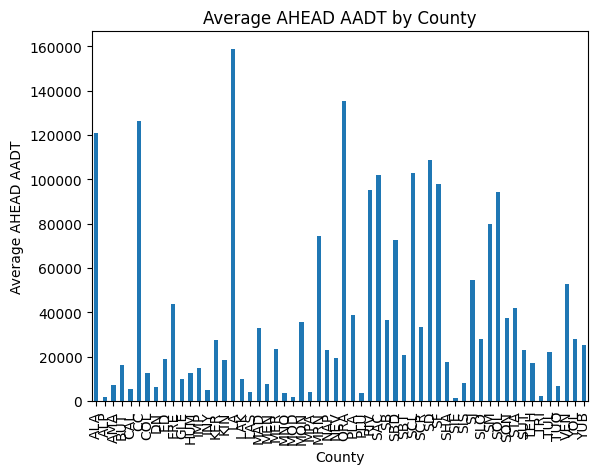

In [ ]:
df_clean.groupby("CNTY")["AHEAD_AADT"].mean().plot(kind="bar")

plt.title("Average AHEAD AADT by County")
plt.xlabel("County")
plt.ylabel("Average AHEAD AADT")
plt.show()

In [ ]:
route_5=df_clean.query("RTE==5 and DISTRICT==12")
route_5

,DISTRICT,RTE,RTE_SFX,CNTY,PM_PFX,PM,PM_SFX,DESCRIPTION,BACK_PEAK_HOUR,BACK_PEAK_MADT,BACK_AADT,AHEAD_PEAK_HOUR,AHEAD_PEAK_MADT,AHEAD_AADT
490,12,5,NaN,ORA,,1.000,,"SAN CLEMENTE, AVENIDA CALIFIA",8500.0,106000.0,103700.0,9500.0,116000.0,112500.0
491,12,5,NaN,ORA,,1.627,,"SAN CLEMENTE, EL CAMINO REAL",9500.0,116000.0,112500.0,10500.0,133000.0,125200.0
492,12,5,NaN,ORA,,2.306,,"SAN CLEMENTE, AVENIDA PRESIDIO",10500.0,133000.0,125200.0,10400.0,133000.0,125700.0
493,12,5,NaN,ORA,,2.663,,"SAN CLEMENTE, AVENIDA PALIZADA",10400.0,133000.0,125700.0,12800.0,158000.0,148900.0
494,12,5,NaN,ORA,,3.393,,"SAN CLEMENTE, AVENIDA PICO",12800.0,158000.0,148900.0,13700.0,166000.0,150900.0
495,12,5,NaN,ORA,,5.801,,"SAN CLEMENTE, CAMINO ESTRELLA",13700.0,166000.0,150900.0,15800.0,192000.0,173500.0
496,12,5,NaN,ORA,,6.780,,JCT RTE 1,15400.0,187000.0,169300.0,16300.0,187000.0,169300.0
497,12,5,NaN,ORA,,7.344,,"SAN JUAN CAPISTRANO, CAMINO CAPISTRANO ON RAMP",14600.0,180000.0,169300.0,16700.0,186000.0,168400.0
498,12,5,NaN,ORA,,8.795,,"SAN JUAN CAPISTRANO, SAN JUAN CREEK ROAD",16700.0,186000.0,168400.0,16600.0,186000.0,168400.0
499,12,5,NaN,ORA,,9.604,,"SAN JUAN CAPISTRANO, JCT. RTE. 74",16600.0,186000.0,168400.0,17600.0,194000.0,175000.0


In [ ]:
route_5=route_5.sort_values(by="PM")
route_5

,DISTRICT,RTE,RTE_SFX,CNTY,PM_PFX,PM,PM_SFX,DESCRIPTION,BACK_PEAK_HOUR,BACK_PEAK_MADT,BACK_AADT,AHEAD_PEAK_HOUR,AHEAD_PEAK_MADT,AHEAD_AADT
490,12,5,NaN,ORA,,1.000,,"SAN CLEMENTE, AVENIDA CALIFIA",8500.0,106000.0,103700.0,9500.0,116000.0,112500.0
491,12,5,NaN,ORA,,1.627,,"SAN CLEMENTE, EL CAMINO REAL",9500.0,116000.0,112500.0,10500.0,133000.0,125200.0
492,12,5,NaN,ORA,,2.306,,"SAN CLEMENTE, AVENIDA PRESIDIO",10500.0,133000.0,125200.0,10400.0,133000.0,125700.0
493,12,5,NaN,ORA,,2.663,,"SAN CLEMENTE, AVENIDA PALIZADA",10400.0,133000.0,125700.0,12800.0,158000.0,148900.0
494,12,5,NaN,ORA,,3.393,,"SAN CLEMENTE, AVENIDA PICO",12800.0,158000.0,148900.0,13700.0,166000.0,150900.0
495,12,5,NaN,ORA,,5.801,,"SAN CLEMENTE, CAMINO ESTRELLA",13700.0,166000.0,150900.0,15800.0,192000.0,173500.0
496,12,5,NaN,ORA,,6.780,,JCT RTE 1,15400.0,187000.0,169300.0,16300.0,187000.0,169300.0
497,12,5,NaN,ORA,,7.344,,"SAN JUAN CAPISTRANO, CAMINO CAPISTRANO ON RAMP",14600.0,180000.0,169300.0,16700.0,186000.0,168400.0
498,12,5,NaN,ORA,,8.795,,"SAN JUAN CAPISTRANO, SAN JUAN CREEK ROAD",16700.0,186000.0,168400.0,16600.0,186000.0,168400.0
499,12,5,NaN,ORA,,9.604,,"SAN JUAN CAPISTRANO, JCT. RTE. 74",16600.0,186000.0,168400.0,17600.0,194000.0,175000.0


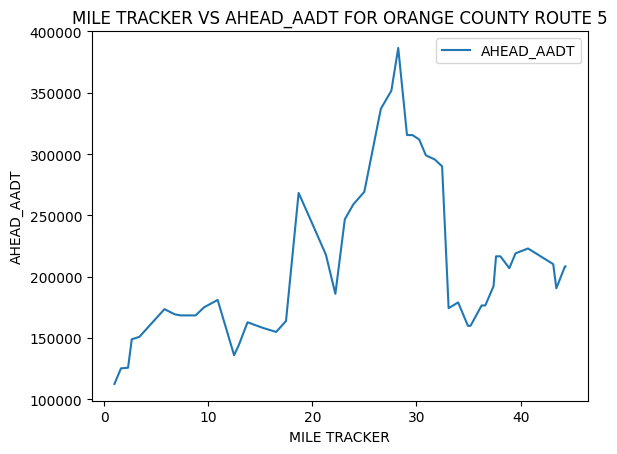

In [ ]:
route_5.plot(x="PM", y="AHEAD_AADT", kind="line")

plt.title("MILE TRACKER VS AHEAD_AADT FOR ORANGE COUNTY ROUTE 5")
plt.xlabel("MILE TRACKER")
plt.ylabel("AHEAD_AADT")


plt.show()

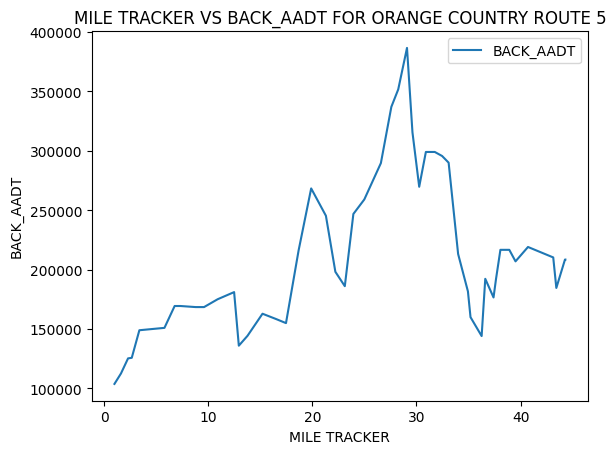

In [ ]:
route_5.plot(x="PM", y="BACK_AADT", kind="line")

plt.title("MILE TRACKER VS BACK_AADT FOR ORANGE COUNTRY ROUTE 5")
plt.xlabel("MILE TRACKER")
plt.ylabel("BACK_AADT")


plt.show()

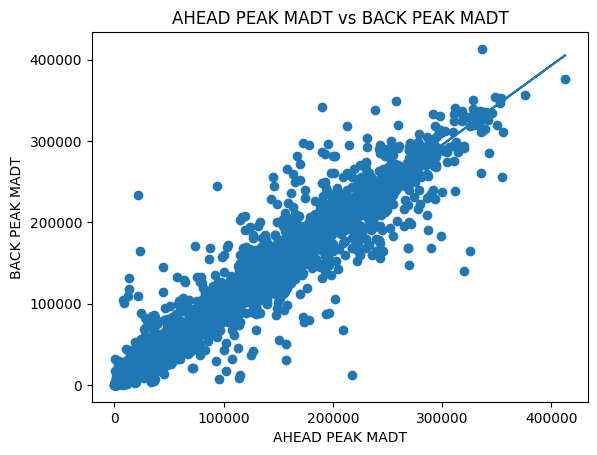

In [ ]:
plt.scatter(df["AHEAD_PEAK_MADT"], df["BACK_PEAK_MADT"])
plt.title("AHEAD PEAK MADT vs BACK PEAK MADT")
plt.xlabel("AHEAD PEAK MADT")
plt.ylabel("BACK PEAK MADT")

clean_df = df[["AHEAD_PEAK_MADT", "BACK_PEAK_MADT"]].dropna()

x = clean_df["AHEAD_PEAK_MADT"]
y = clean_df["BACK_PEAK_MADT"]

m, b = np.polyfit(x, y, 1)
y_pred = m*x + b

plt.plot(x, m*x + b)
plt.show()

In [ ]:
m,b

(np.float64(0.9767143302052158), np.float64(1971.7712486975115))

In [ ]:
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - (ss_res / ss_tot)
r2

np.float64(0.9554027639735132)